# HA_Calc: ピクセル同定とガンマ線エネルギー

`HA_CenterGravity` が求めた重心から、どのピクセル結晶が光ったかを決め、エネルギーを較正します。
SMILE_tool_box の `HA_Calc_s2` に相当します。

1. **MDF(Multi-Dimensional Fit)変換**で重心の歪みを補正する。変換後の座標は −0.4〜0.4 の範囲で 8 × 8 の格子になり、
   `x_id = floor(10 x + 4)` などでピクセルを決める
2. ピクセルごとの較正係数で 4 ch の和をエネルギー [keV] に変換し、PMT ゲインの補正(`Flag_Modify_PMT_Gain`)を掛ける
3. ピクセルの位置から吸収点 `Pg` [mm] を求める(ピクセルピッチ 6 mm、PMT 間隔 54 mm)
4. **シングルヒット判定**: `SingleHit_Eth` を超える有効ヒットがちょうど 1 つで、
   それ以外の PMT の生エネルギーがどれも `SingleHit_ADCth` 以下のときだけ `Eg`, `Pg` を有効にする

再構成ツリー `single_hit` には、シングルヒットの PMT について
`HA_Pixel`(HA 番号・PMT・ピクセル x・ピクセル y)、`HA_Gravity`(重心)、`HA_MDF`(MDF 変換後の座標)が入っています。

### パラメータ

| パラメータ | 値 | 意味 |
|---|---|---|
| `parameter_dir` | `param/20190528` | MDF・較正係数のディレクトリ |
| `Flag_Modify_PMT_Gain`, `Modified_Parameter_Data_Dir` | `True`, `param/20190528` | PMT ゲインの補正 |
| `SingleHit_Eth` | 50 keV | 有効ヒットとみなすエネルギー |
| `SingleHit_ADCth` | 1000 | 他の PMT に許す生エネルギーの上限 |

In [1]:
import sys
from pathlib import Path
here = Path.cwd().resolve()
sys.path.insert(0, str(next(p for p in [here, *here.parents] if (p / "tutorial_utils.py").exists())))
import tutorial_utils as tu

import numpy as np
import matplotlib.pyplot as plt
ROOT = tu.setup_pyroot()

## 1. データのダウンロード

このチュートリアルでは 20190701 の較正データ **Per02**(線源を TPC の上方 z = −1626 mm に置いた測定)を使います。
生データ(約 17 GB)とパラメータはリポジトリに含まれていないので、研究室サーバーから手元にコピーします。

```bash
mkdir -p ~/smile2p_data
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/Per02_ETCC ~/smile2p_data/
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/param ~/smile2p_data/
```

(`<user>` は自分のアカウント名)

- 途中で切れても同じコマンドで続きからコピーされます。
- `~/smile2p_data` 以外に置いた場合は、環境変数 `SMILE2P_DATA` にその場所を設定してください。
- サーバー上で実行する場合はコピーしなくても動きます(サーバー上の場所をそのまま使います)。
  ただし実行時間の大半は生データの読み込みなので、**手元のディスクにコピーした方が大幅に速く**なります
  (ネットワーク越しの場所から読むと約 10 倍遅い)。

In [2]:
tu.print_download_instructions("Per02")
DATA_TOP = tu.check_data("Per02")

# 生データ(Per02)とパラメータを ~/smile2p_data にコピーする
mkdir -p ~/smile2p_data
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/Per02_ETCC ~/smile2p_data/
rsync -av --progress <user>@ramune:/home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/param ~/smile2p_data/
data OK: /home/onoda/hikaru3_analysis2/sm2+_cal_rawdata  (Per02: 554 raw files)


## 2. 再構成ツリーを読む

In [3]:
# 全チェーンの出力(DataIO と共有、Per02 の先頭 50000 イベント)
OUT = tu.get_reconstructed("Per02", 50000)
ev = tu.load_single_hit(OUT, branches=['err_flag', 'Eg', 'HA_Pixel', 'HA_Gravity', 'HA_MDF'])
print("err_flag == 0:", len(ev["err_flag"]))

Per02_50000.root は既にあるので再実行しません(overwrite=True で作り直し)


err_flag == 0: 26697


## 3. MDF 変換の前後

全 PMT のシングルヒットを重ねて描きます。重心(左)は PMT ごとに歪みが違うのでぼやけますが、
MDF 変換後(中)は全 PMT 共通の 8 × 8 の格子になります(赤線がピクセルの境界)。
右はピクセルの割り当て(HA_Pixel の x, y)ごとのヒット数です。

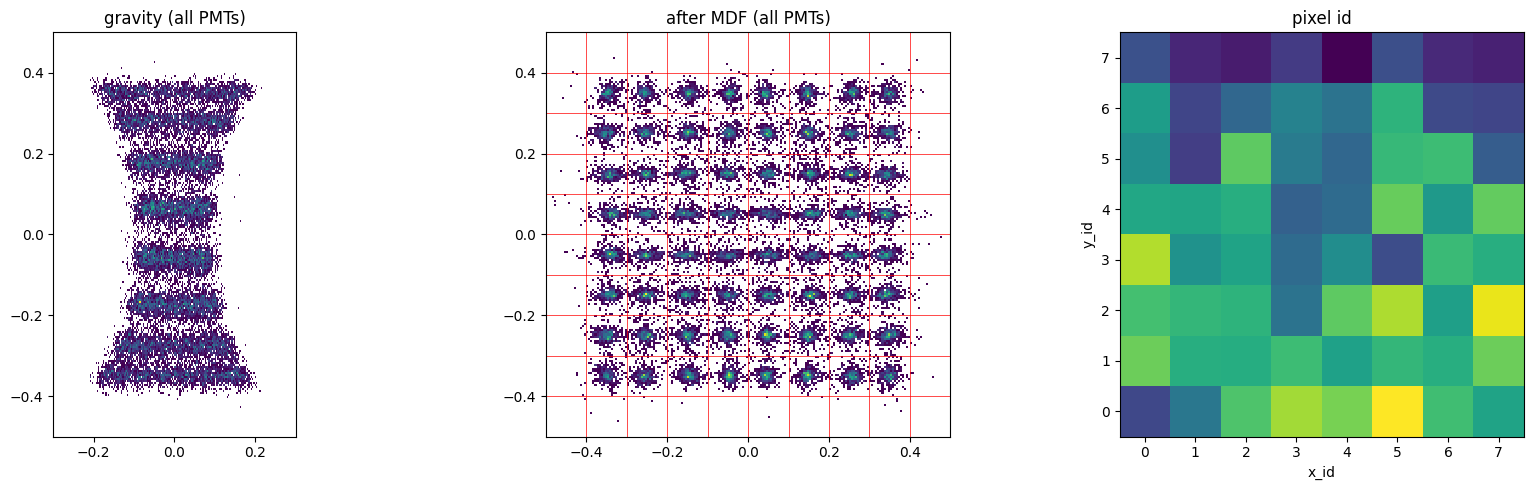

In [4]:
grv, mdf, pix = ev["HA_Gravity"], ev["HA_MDF"], ev["HA_Pixel"]
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
ax[0].hist2d(grv[:, 0], grv[:, 1], bins=200, range=[[-0.3, 0.3], [-0.5, 0.5]], cmin=1)
ax[0].set_title("gravity (all PMTs)")
ax[1].hist2d(mdf[:, 0], mdf[:, 1], bins=200, range=[[-0.5, 0.5], [-0.5, 0.5]], cmin=1)
for b in np.arange(-0.4, 0.41, 0.1):
    ax[1].axvline(b, color="r", lw=0.5); ax[1].axhline(b, color="r", lw=0.5)
ax[1].set_title("after MDF (all PMTs)")
ax[2].hist2d(pix[:, 2], pix[:, 3], bins=8, range=[[-0.5, 7.5], [-0.5, 7.5]])
ax[2].set_title("pixel id"); ax[2].set_xlabel("x_id"); ax[2].set_ylabel("y_id")
for a in ax: a.set_aspect("equal")
fig.tight_layout(); plt.show()

## 4. エネルギースペクトル

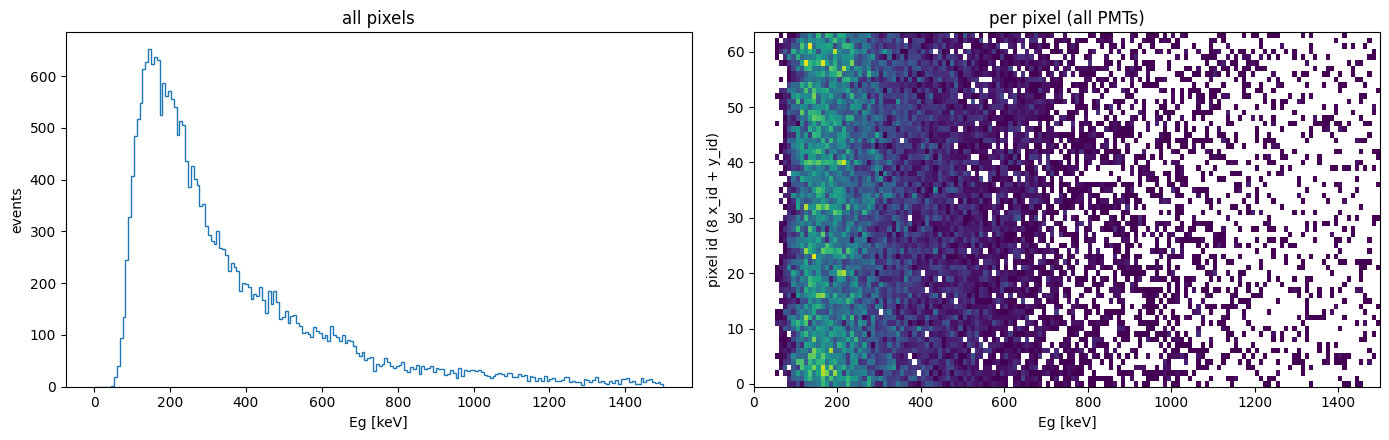

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].hist(ev["Eg"], bins=200, range=(0, 1500), histtype="step")
ax[0].set_xlabel("Eg [keV]"); ax[0].set_ylabel("events"); ax[0].set_title("all pixels")
pid = pix[:, 2] * 8 + pix[:, 3]
ax[1].hist2d(ev["Eg"], pid, bins=[150, 64], range=[[0, 1500], [-0.5, 63.5]], cmin=1)
ax[1].set_xlabel("Eg [keV]"); ax[1].set_ylabel("pixel id (8 x_id + y_id)"); ax[1].set_title("per pixel (all PMTs)")
fig.tight_layout(); plt.show()